In [ ]:
!pip install -q psycopg2-binary

Step 2 — Install the PostgreSQL library

In [ ]:
import psycopg2
from google.colab import userdata

# Get the connection string securely from Colab Secrets
DATABASE_URL = userdata.get("DW_WAREHOUSE_DATABASE_URL")

# Connect to the central Neon Data Warehouse
conn = psycopg2.connect(DATABASE_URL)

# Create a cursor to execute SQL queries
cursor = conn.cursor()

print("Successfully connected to Neon PostgreSQL!")

Successfully connected to Neon PostgreSQL!


Step 4 — Verify the connection

In [ ]:
cursor.execute("""
SELECT
    current_database(),
    current_schema(),
    current_setting('search_path');
""")

print("Database, schema, search path:", cursor.fetchone())

Database, schema, search path: ('neondb', 'public', '"$user", public')


chnage from public to dw

In [ ]:
cursor.execute("""
SELECT schema_name
FROM information_schema.schemata
WHERE schema_name IN ('dw', 'meta')
ORDER BY schema_name;
""")

print("Warehouse schemas:", cursor.fetchall())

Warehouse schemas: [('dw',), ('meta',)]


Step 6 — Display all existing Data Warehouse tables

In [ ]:
cursor.execute("SET search_path TO dw, meta, public;")

cursor.execute("SELECT current_schema(), current_setting('search_path');")

print(cursor.fetchone())

('dw', 'dw, meta, public')


In [ ]:
cursor.execute("""
SELECT table_name
FROM information_schema.tables
WHERE table_schema = 'dw'
AND table_type = 'BASE TABLE'
ORDER BY table_name;
""")

tables = cursor.fetchall()

print("CENTRAL DATA WAREHOUSE TABLES")
print("=" * 55)

for i, table in enumerate(tables, start=1):
    print(f"{i}. {table[0]}")

print("=" * 55)
print("Total tables:", len(tables))

CENTRAL DATA WAREHOUSE TABLES
1. Dim_Account
2. Dim_Cost_Center
3. Dim_Customer
4. Dim_Date
5. Dim_Fiscal_Period
6. Dim_Location
7. Dim_Movement_Type
8. Dim_Product
9. Dim_PurchaseOrder
10. Dim_SalesOrder
11. Dim_Supplier
12. Dim_Warehouse
13. Fact_Budget
14. Fact_Inventory_Balance
15. Fact_Inventory_Movement
16. Fact_Journal_Entry_Line
17. Fact_Payment
18. Fact_Purchase
19. Fact_Sales
20. Fact_Stock_Count
Total tables: 20


Step 11 — Understand what data is available

In [ ]:
import pandas as pd

cursor.execute("""
SELECT
    table_name,
    column_name,
    data_type,
    is_nullable
FROM information_schema.columns
WHERE table_schema = 'dw'
ORDER BY table_name, ordinal_position;
""")

columns = cursor.fetchall()

column_report = pd.DataFrame(
    columns,
    columns=["Table Name", "Column Name", "Data Type", "Nullable"]
)

print("Total tables:", column_report["Table Name"].nunique())
print("Total columns:", len(column_report))

display(column_report)

Total tables: 20
Total columns: 152


,Table Name,Column Name,Data Type,Nullable
0,Dim_Account,account_key,bigint,NO
1,Dim_Account,account_id,bigint,YES
2,Dim_Account,account_code,text,YES
3,Dim_Account,account_name,text,YES
4,Dim_Account,account_type,text,YES
...,...,...,...,...
147,Fact_Stock_Count,product_key,bigint,YES
148,Fact_Stock_Count,warehouse_key,bigint,YES
149,Fact_Stock_Count,location_key,bigint,YES
150,Fact_Stock_Count,date_key,bigint,YES


In [ ]:
import pandas as pd

cursor.execute("""
SELECT
    table_name,
    column_name,
    data_type
FROM information_schema.columns
WHERE table_schema = 'dw'
AND table_name IN ('Fact_Sales', 'Dim_Date')
ORDER BY table_name, ordinal_position;
""")

result = cursor.fetchall()

sales_columns = pd.DataFrame(
    result,
    columns=["Table Name", "Column Name", "Data Type"]
)

display(sales_columns)

,Table Name,Column Name,Data Type
0,Dim_Date,date_key,bigint
1,Dim_Date,full_date,timestamp without time zone
2,Dim_Date,day,bigint
3,Dim_Date,day_name,text
4,Dim_Date,month,bigint
5,Dim_Date,month_name,text
6,Dim_Date,quarter,bigint
7,Dim_Date,year,bigint
8,Fact_Sales,sales_key,bigint
9,Fact_Sales,order_line_id,bigint


In [ ]:
import pandas as pd

query = """
SELECT
    DATE_TRUNC('month', d.full_date)::date AS sales_month,
    COUNT(*) AS total_sales_lines,
    SUM(f.quantity) AS total_quantity,
    SUM(f.line_total) AS total_sales
FROM dw."Fact_Sales" f
JOIN dw."Dim_Date" d
    ON f.date_key = d.date_key
WHERE d.full_date IS NOT NULL
GROUP BY DATE_TRUNC('month', d.full_date)
ORDER BY sales_month;
"""

cursor.execute(query)

rows = cursor.fetchall()
columns = [desc[0] for desc in cursor.description]

monthly_sales = pd.DataFrame(rows, columns=columns)

monthly_sales["sales_month"] = pd.to_datetime(
    monthly_sales["sales_month"]
)

monthly_sales["total_sales"] = pd.to_numeric(
    monthly_sales["total_sales"]
)

print("MONTHLY SALES DATASET")
print("=" * 55)

display(monthly_sales)

print("Total months:", len(monthly_sales))
print("First month:", monthly_sales["sales_month"].min())
print("Last month:", monthly_sales["sales_month"].max())
print("Total sales:", monthly_sales["total_sales"].sum())

MONTHLY SALES DATASET


,sales_month,total_sales_lines,total_quantity,total_sales
0,2023-11-01,8421,25388,2.554127e+09
1,2023-12-01,8100,24519,2.450879e+09
2,2024-01-01,8475,25325,2.544719e+09
3,2024-02-01,8043,24126,2.440426e+09
4,2024-03-01,8484,25384,2.510161e+09
5,2024-04-01,8220,24871,2.475215e+09
6,2024-05-01,8274,24819,2.476019e+09
7,2024-06-01,8568,25666,2.542668e+09
8,2024-07-01,8478,25324,2.529151e+09
9,2024-08-01,8322,24967,2.487600e+09


Total months: 36
First month: 2023-11-01 00:00:00
Last month: 2026-10-01 00:00:00
Total sales: 89849774124.37


In [ ]:
import pandas as pd

print("=" * 60)
print("PHASE 1 - MONTHLY SALES DATA VALIDATION")
print("=" * 60)

# Sort the dataset chronologically
monthly_sales = monthly_sales.sort_values(
    "sales_month"
).reset_index(drop=True)

# 1. Check missing values
print("\n1. MISSING VALUES")
print(monthly_sales.isnull().sum())

# 2. Check duplicate months
duplicate_months = monthly_sales["sales_month"].duplicated().sum()

print("\n2. DUPLICATE MONTHS:", duplicate_months)

# 3. Check missing calendar months
expected_months = pd.date_range(
    start=monthly_sales["sales_month"].min(),
    end=monthly_sales["sales_month"].max(),
    freq="MS"
)

missing_months = expected_months.difference(
    pd.DatetimeIndex(monthly_sales["sales_month"])
)

print("\n3. MISSING CALENDAR MONTHS:", len(missing_months))
print(missing_months)

# 4. Check invalid sales
invalid_sales = (
    (monthly_sales["total_sales"] <= 0) |
    (monthly_sales["total_sales"].isnull())
).sum()

print("\n4. INVALID MONTHLY SALES:", invalid_sales)

# 5. Verify totals and date range
print("\n5. DATASET SUMMARY")
print("Total months:", len(monthly_sales))
print("First month:", monthly_sales["sales_month"].min())
print("Last month:", monthly_sales["sales_month"].max())
print("Total sales:", monthly_sales["total_sales"].sum())

# 6. Overall validation result
passed = (
    monthly_sales.isnull().sum().sum() == 0
    and duplicate_months == 0
    and len(missing_months) == 0
    and invalid_sales == 0
    and len(monthly_sales) == 36
)

print("\n" + "=" * 60)
print("VALIDATION STATUS:", "PASS" if passed else "REVIEW REQUIRED")
print("=" * 60)

PHASE 1 - MONTHLY SALES DATA VALIDATION

1. MISSING VALUES
sales_month          0
total_sales_lines    0
total_quantity       0
total_sales          0
dtype: int64

2. DUPLICATE MONTHS: 0

3. MISSING CALENDAR MONTHS: 0
DatetimeIndex([], dtype='datetime64[ns]', freq='MS')

4. INVALID MONTHLY SALES: 0

5. DATASET SUMMARY
Total months: 36
First month: 2023-11-01 00:00:00
Last month: 2026-10-01 00:00:00
Total sales: 89849774124.37

VALIDATION STATUS: PASS


In [ ]:
# ==========================================================
# PHASE 1 - CELL 15
# TIME-BASED TRAIN / TEST SPLIT
# ==========================================================

# Ensure data is in chronological order
monthly_sales = monthly_sales.sort_values(
    "sales_month"
).reset_index(drop=True)

# Reserve the last 3 months for testing
train_data = monthly_sales.iloc[:-3].copy()
test_data = monthly_sales.iloc[-3:].copy()

print("=" * 60)
print("SALES FORECASTING - TRAIN / TEST SPLIT")
print("=" * 60)

print("\nTRAINING DATA")
print("Months:", len(train_data))
print("Start:", train_data["sales_month"].min().date())
print("End:", train_data["sales_month"].max().date())

print("\nTESTING DATA")
print("Months:", len(test_data))
print("Start:", test_data["sales_month"].min().date())
print("End:", test_data["sales_month"].max().date())

print("\nACTUAL TEST SALES")
display(test_data[["sales_month", "total_sales"]])

# Validate split
assert len(train_data) == 33
assert len(test_data) == 3
assert train_data["sales_month"].max() < test_data["sales_month"].min()

print("\nSTATUS: PASS - No future data leakage in split")

SALES FORECASTING - TRAIN / TEST SPLIT

TRAINING DATA
Months: 33
Start: 2023-11-01
End: 2026-07-01

TESTING DATA
Months: 3
Start: 2026-08-01
End: 2026-10-01

ACTUAL TEST SALES


,sales_month,total_sales
33,2026-08-01,2.479192e+09
34,2026-09-01,2.483765e+09
35,2026-10-01,2.542442e+09



STATUS: PASS - No future data leakage in split


In [ ]:
# ==========================================================
# PHASE 1 - CELL 16
# SEASONAL NAIVE BASELINE FORECAST
# ==========================================================

import numpy as np
import pandas as pd
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Get the training sales series
train_series = train_data.set_index("sales_month")["total_sales"]

# Predict each test month using the same month last year
baseline_predictions = []

for test_month in test_data["sales_month"]:
    previous_year_month = test_month - pd.DateOffset(years=1)

    prediction = train_series.loc[previous_year_month]
    baseline_predictions.append(float(prediction))

# Actual test values
actual_sales = test_data["total_sales"].astype(float).to_numpy()

# Calculate evaluation metrics
baseline_mae = mean_absolute_error(
    actual_sales, baseline_predictions
)

baseline_rmse = np.sqrt(
    mean_squared_error(actual_sales, baseline_predictions)
)

# Comparison table
baseline_results = pd.DataFrame({
    "Month": test_data["sales_month"].to_numpy(),
    "Actual_Sales": actual_sales,
    "Baseline_Prediction": baseline_predictions
})

baseline_results["Absolute_Error"] = abs(
    baseline_results["Actual_Sales"]
    - baseline_results["Baseline_Prediction"]
)

print("=" * 65)
print("SEASONAL NAIVE BASELINE - TEST RESULTS")
print("=" * 65)

display(baseline_results)

print(f"\nBaseline MAE: {baseline_mae:,.2f}")
print(f"Baseline RMSE: {baseline_rmse:,.2f}")

print("\nSTATUS: BASELINE EVALUATION COMPLETED")


SEASONAL NAIVE BASELINE - TEST RESULTS


,Month,Actual_Sales,Baseline_Prediction,Absolute_Error
0,2026-08-01,2.479192e+09,2.488955e+09,9763264.17
1,2026-09-01,2.483765e+09,2.473978e+09,9786835.58
2,2026-10-01,2.542442e+09,2.482502e+09,59940063.44



Baseline MAE: 26,496,721.06
Baseline RMSE: 35,514,854.56

STATUS: BASELINE EVALUATION COMPLETED


In [ ]:
# ==========================================================
# PHASE 1 - CELL 17
# RIDGE REGRESSION MONTHLY SALES FORECASTING
# ==========================================================

import numpy as np
import pandas as pd
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Keep the original chronological month positions
all_months = monthly_sales["sales_month"]

def create_features(dates):
    dates = pd.to_datetime(dates)
    month_numbers = dates.dt.month

    features = pd.DataFrame({
        "time_index": (
            (dates.dt.year - all_months.iloc[0].year) * 12
            + dates.dt.month - all_months.iloc[0].month
        ).to_numpy()
    })

    # One-hot encode months, using January as the reference
    for month in range(2, 13):
        features[f"month_{month}"] = (
            month_numbers == month
        ).astype(int).to_numpy()

    return features

X_train = create_features(train_data["sales_month"])
X_test = create_features(test_data["sales_month"])

# Scale the target to billions for numerical stability
y_train = train_data["total_sales"].astype(float).to_numpy() / 1e9
y_test = test_data["total_sales"].astype(float).to_numpy()

# Train using historical training data only
ridge_model = Ridge(alpha=1.0)
ridge_model.fit(X_train, y_train)

# Predict the held-out months
ridge_predictions = ridge_model.predict(X_test) * 1e9

# Evaluation
ridge_mae = mean_absolute_error(y_test, ridge_predictions)
ridge_rmse = np.sqrt(
    mean_squared_error(y_test, ridge_predictions)
)

ridge_results = pd.DataFrame({
    "Month": test_data["sales_month"].to_numpy(),
    "Actual_Sales": y_test,
    "Ridge_Prediction": ridge_predictions
})

ridge_results["Absolute_Error"] = abs(
    ridge_results["Actual_Sales"]
    - ridge_results["Ridge_Prediction"]
)

print("=" * 65)
print("RIDGE REGRESSION - TEST RESULTS")
print("=" * 65)

display(ridge_results)

print(f"\nRidge MAE: {ridge_mae:,.2f}")
print(f"Ridge RMSE: {ridge_rmse:,.2f}")

print("\nBASELINE VS RIDGE")
comparison = pd.DataFrame({
    "Model": ["Seasonal Naive", "Ridge Regression"],
    "MAE": [baseline_mae, ridge_mae],
    "RMSE": [baseline_rmse, ridge_rmse]
})

display(comparison)

print("\nSTATUS: RIDGE MODEL EVALUATION COMPLETED")

RIDGE REGRESSION - TEST RESULTS


,Month,Actual_Sales,Ridge_Prediction,Absolute_Error
0,2026-08-01,2.479192e+09,2.481748e+09,2.556013e+06
1,2026-09-01,2.483765e+09,2.457171e+09,2.659440e+07
2,2026-10-01,2.542442e+09,2.507302e+09,3.513946e+07



Ridge MAE: 21,429,954.87
Ridge RMSE: 25,485,789.75

BASELINE VS RIDGE


,Model,MAE,RMSE
0,Seasonal Naive,2.649672e+07,3.551485e+07
1,Ridge Regression,2.142995e+07,2.548579e+07



STATUS: RIDGE MODEL EVALUATION COMPLETED


In [ ]:


# ==========================================================
# PHASE 1 - CELL 18
# ROLLING-ORIGIN VALIDATION
# Baseline vs Ridge Regression
# ==========================================================

import numpy as np
import pandas as pd
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error

results = []

# Use only the 33 training months
history = train_data.sort_values("sales_month").reset_index(drop=True)

# Multiple historical 3-month validation windows
for train_end in range(21, len(history) - 2, 3):

    fold_train = history.iloc[:train_end].copy()
    fold_test = history.iloc[train_end:train_end + 3].copy()

    actual = fold_test["total_sales"].astype(float).to_numpy()

    # Seasonal naive baseline
    train_lookup = fold_train.set_index("sales_month")["total_sales"]

    baseline_pred = np.array([
        float(train_lookup.loc[month - pd.DateOffset(years=1)])
        for month in fold_test["sales_month"]
    ])

    # Ridge regression
    X_fold_train = create_features(fold_train["sales_month"])
    X_fold_test = create_features(fold_test["sales_month"])

    model = Ridge(alpha=1.0)
    model.fit(
        X_fold_train,
        fold_train["total_sales"].astype(float).to_numpy() / 1e9
    )

    ridge_pred = model.predict(X_fold_test) * 1e9

    # Save metrics for both models
    for model_name, predictions in [
        ("Seasonal Naive", baseline_pred),
        ("Ridge Regression", ridge_pred)
    ]:
        results.append({
            "Train_End": fold_train["sales_month"].max().date(),
            "Test_Start": fold_test["sales_month"].min().date(),
            "Test_End": fold_test["sales_month"].max().date(),
            "Model": model_name,
            "MAE": mean_absolute_error(actual, predictions),
            "RMSE": np.sqrt(mean_squared_error(actual, predictions))
        })

rolling_results = pd.DataFrame(results)

print("=" * 70)
print("ROLLING-ORIGIN VALIDATION RESULTS")
print("=" * 70)

display(rolling_results)

print("\nAVERAGE METRICS ACROSS FOLDS")

rolling_summary = (
    rolling_results.groupby("Model")[["MAE", "RMSE"]]
    .mean()
    .sort_values("MAE")
)

display(rolling_summary)

print("\nSTATUS: ROLLING VALIDATION COMPLETED")


ROLLING-ORIGIN VALIDATION RESULTS


,Train_End,Test_Start,Test_End,Model,MAE,RMSE
0,2025-07-01,2025-08-01,2025-10-01,Seasonal Naive,4.507426e+07,5.761499e+07
1,2025-07-01,2025-08-01,2025-10-01,Ridge Regression,2.221312e+07,3.095444e+07
2,2025-10-01,2025-11-01,2026-01-01,Seasonal Naive,7.514067e+07,7.523276e+07
3,2025-10-01,2025-11-01,2026-01-01,Ridge Regression,6.683137e+07,7.703851e+07
4,2026-01-01,2026-02-01,2026-04-01,Seasonal Naive,2.925926e+07,3.345991e+07
5,2026-01-01,2026-02-01,2026-04-01,Ridge Regression,4.934969e+07,5.695539e+07
6,2026-04-01,2026-05-01,2026-07-01,Seasonal Naive,6.205543e+07,6.995575e+07
7,2026-04-01,2026-05-01,2026-07-01,Ridge Regression,6.027702e+07,6.548939e+07



AVERAGE METRICS ACROSS FOLDS


,MAE,RMSE
Model,,
Ridge Regression,4.966780e+07,5.760943e+07
Seasonal Naive,5.288241e+07,5.906585e+07



STATUS: ROLLING VALIDATION COMPLETED


In [ ]:
# ==========================================================
# PHASE 1 - CELL 19
# FINAL RIDGE MODEL AND 3-MONTH SALES FORECAST
# ==========================================================

import numpy as np
import pandas as pd
from sklearn.linear_model import Ridge

# 1. Use all 36 months for final training
full_data = monthly_sales.sort_values(
    "sales_month"
).reset_index(drop=True)

X_full = create_features(full_data["sales_month"])
y_full = full_data["total_sales"].astype(float).to_numpy() / 1e9

# 2. Train final model
final_ridge_model = Ridge(alpha=1.0)
final_ridge_model.fit(X_full, y_full)

# 3. Generate the next three calendar months
last_month = full_data["sales_month"].max()

future_months = pd.date_range(
    start=last_month + pd.DateOffset(months=1),
    periods=3,
    freq="MS"
)

# 4. Prepare future features
X_future = create_features(pd.Series(future_months))

# 5. Predict future sales
future_predictions = final_ridge_model.predict(X_future) * 1e9

# 6. Store forecasts in a DataFrame
forecast_results = pd.DataFrame({
    "forecast_month": future_months,
    "predicted_sales": future_predictions,
    "model_name": "Ridge Regression"
})

print("=" * 65)
print("FINAL 3-MONTH SALES FORECAST")
print("=" * 65)

display(forecast_results)

print("\nMODEL INFORMATION")
print("Model: Ridge Regression")
print("Training months:", len(full_data))
print("Training end:", last_month.date())
print("Forecast months:", len(forecast_results))

# 7. Validate forecast output
assert len(forecast_results) == 3
assert forecast_results["predicted_sales"].notna().all()
assert (forecast_results["predicted_sales"] > 0).all()

print("\nSTATUS: FINAL FORECAST GENERATED SUCCESSFULLY")

FINAL 3-MONTH SALES FORECAST


,forecast_month,predicted_sales,model_name
0,2026-11-01,2.508635e+09,Ridge Regression
1,2026-12-01,2.510715e+09,Ridge Regression
2,2027-01-01,2.490819e+09,Ridge Regression



MODEL INFORMATION
Model: Ridge Regression
Training months: 36
Training end: 2026-10-01
Forecast months: 3

STATUS: FINAL FORECAST GENERATED SUCCESSFULLY


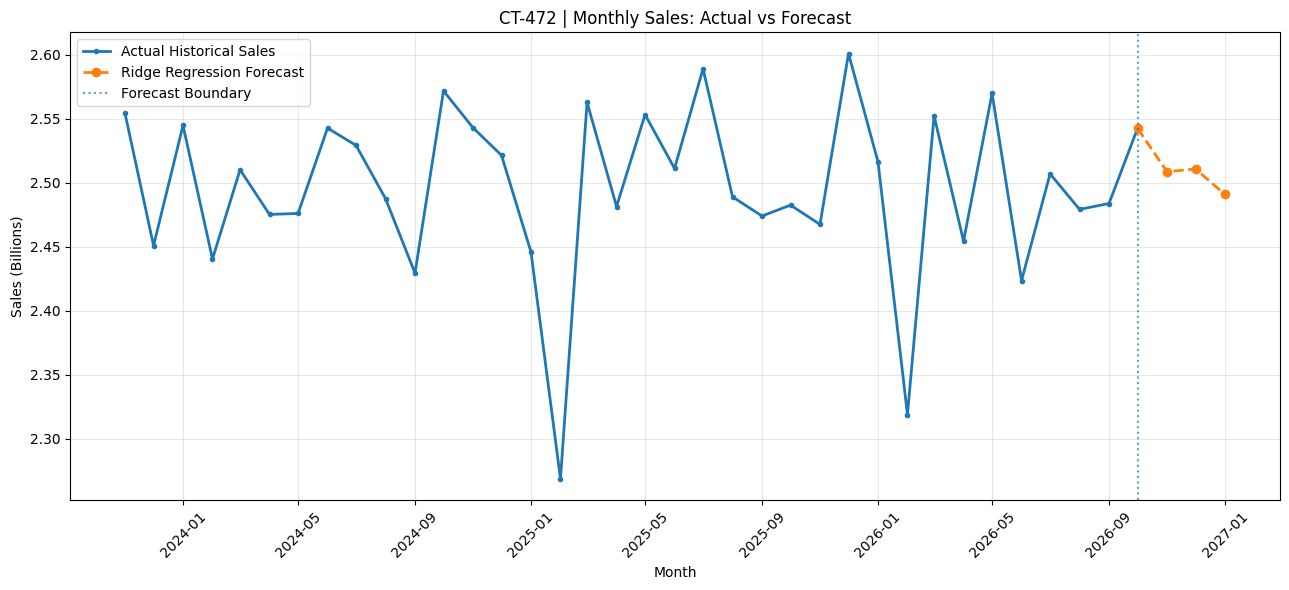

Chart saved: /content/CT472_Sales_Forecast.png
STATUS: FORECAST VISUALIZATION COMPLETED


In [ ]:
# ==========================================================
# PHASE 1 - CELL 20
# HISTORICAL SALES VS FUTURE FORECAST VISUALIZATION
# ==========================================================

import matplotlib.pyplot as plt
import pandas as pd

# Prepare historical and forecast data
history = monthly_sales.sort_values("sales_month").copy()
future = forecast_results.sort_values("forecast_month").copy()

# Convert sales to billions for easier reading
historical_values = history["total_sales"].astype(float) / 1e9
forecast_values = future["predicted_sales"].astype(float) / 1e9

plt.figure(figsize=(13, 6))

# Historical sales
plt.plot(
    history["sales_month"],
    historical_values,
    marker="o",
    markersize=3,
    linewidth=2,
    label="Actual Historical Sales"
)

# Forecast, connected to the final historical month
forecast_dates = pd.concat([
    history["sales_month"].tail(1),
    future["forecast_month"]
])

forecast_plot_values = pd.concat([
    historical_values.tail(1),
    forecast_values
])

plt.plot(
    forecast_dates,
    forecast_plot_values,
    marker="o",
    linestyle="--",
    linewidth=2,
    label="Ridge Regression Forecast"
)

# Mark the forecast starting point
plt.axvline(
    x=history["sales_month"].max(),
    linestyle=":",
    alpha=0.7,
    label="Forecast Boundary"
)

plt.title("CT-472 | Monthly Sales: Actual vs Forecast")
plt.xlabel("Month")
plt.ylabel("Sales (Billions)")
plt.legend()
plt.grid(alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()

plt.savefig(
    "/content/CT472_Sales_Forecast.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

print("Chart saved: /content/CT472_Sales_Forecast.png")
print("STATUS: FORECAST VISUALIZATION COMPLETED")


In [ ]:
# ==========================================================
# PHASE 1 - CELL 21
# SAVE FORECASTING DELIVERABLES TO GOOGLE DRIVE
# ==========================================================

from google.colab import drive
from pathlib import Path
import shutil
import pandas as pd

# Mount Drive if needed
drive.mount("/content/drive", force_remount=False)

# Create dedicated AI forecasting folder
output_dir = Path(
    "/content/drive/MyDrive/Enterprise_DW_Project/AI_Forecasting"
)
output_dir.mkdir(parents=True, exist_ok=True)

# 1. Save future predictions
forecast_results.to_csv(
    output_dir / "Sales_Forecast_3_Months.csv",
    index=False
)

# 2. Save model comparison
comparison.to_csv(
    output_dir / "Model_Comparison.csv",
    index=False
)

# 3. Save rolling validation results
rolling_results.to_csv(
    output_dir / "Rolling_Validation.csv",
    index=False
)

# 4. Save historical monthly sales
monthly_sales.to_csv(
    output_dir / "Historical_Monthly_Sales.csv",
    index=False
)

# 5. Save forecast chart
chart_source = Path("/content/CT472_Sales_Forecast.png")

if chart_source.exists():
    shutil.copy2(
        chart_source,
        output_dir / "Sales_Forecast_Chart.png"
    )
else:
    print("WARNING: Chart not found in Colab.")

# 6. Verify saved files
print("=" * 65)
print("CT-472 - AI FORECASTING DELIVERABLES")
print("=" * 65)

for file in sorted(output_dir.iterdir()):
    if file.is_file():
        print("SAVED:", file.name)

print("\nGoogle Drive folder:", output_dir)
print("\nSTATUS: FORECAST DELIVERABLES SAVED")


Mounted at /content/drive
CT-472 - AI FORECASTING DELIVERABLES
SAVED: Historical_Monthly_Sales.csv
SAVED: Model_Comparison.csv
SAVED: Rolling_Validation.csv
SAVED: Sales_Forecast_3_Months.csv
SAVED: Sales_Forecast_Chart.png

Google Drive folder: /content/drive/MyDrive/Enterprise_DW_Project/AI_Forecasting

STATUS: FORECAST DELIVERABLES SAVED


PHASE 2 - MONTHLY SALES ANOMALY EXPLORATION

1. DATASET SUMMARY
Total months: 36
Start: 2023-11-01
End: 2026-10-01

2. SALES STATISTICS
count    3.600000e+01
mean     2.495827e+09
std      6.801482e+07
min      2.268690e+09
25%      2.472340e+09
50%      2.497951e+09
75%      2.543425e+09
max      2.600875e+09
Name: total_sales, dtype: float64

3. FIVE LOWEST SALES MONTHS


,sales_month,total_sales
15,2025-02-01,2.268690e+09
27,2026-02-01,2.318838e+09
31,2026-06-01,2.423567e+09
10,2024-09-01,2.429364e+09
3,2024-02-01,2.440426e+09



4. FIVE HIGHEST SALES MONTHS


,sales_month,total_sales
25,2025-12-01,2.600875e+09
20,2025-07-01,2.589027e+09
11,2024-10-01,2.571756e+09
30,2026-05-01,2.569711e+09
16,2025-03-01,2.562788e+09


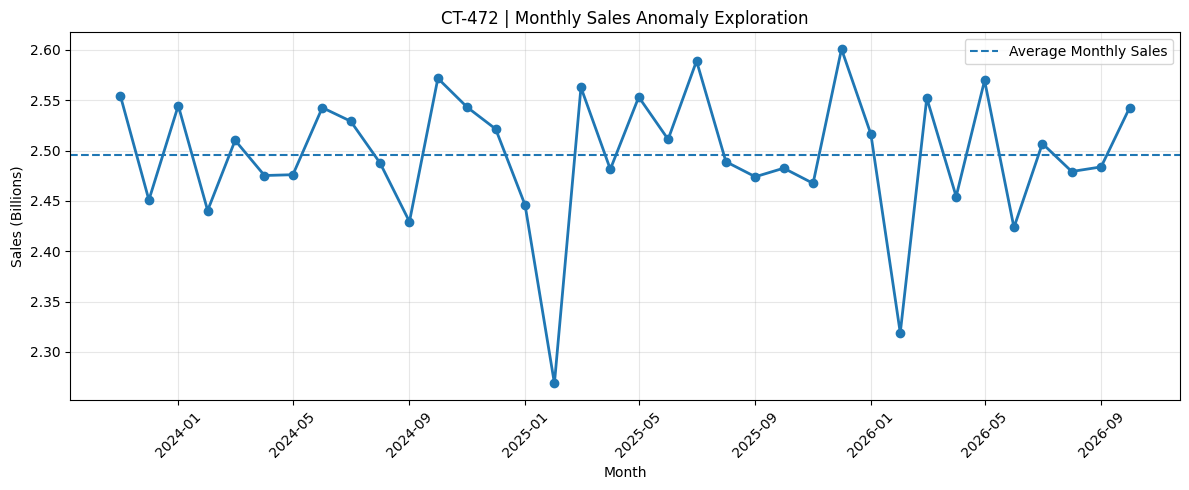


STATUS: ANOMALY DATA EXPLORATION COMPLETED


In [ ]:
# ==========================================================
# CT-472 | PHASE 2 - CELL 22
# MONTHLY SALES ANOMALY DATA EXPLORATION
# READ-ONLY - NO DATABASE MODIFICATIONS
# ==========================================================

import pandas as pd
import matplotlib.pyplot as plt

# Use the already validated monthly sales dataset
anomaly_data = monthly_sales.copy()

anomaly_data = anomaly_data.sort_values(
    "sales_month"
).reset_index(drop=True)

# Convert sales to numeric values
anomaly_data["total_sales"] = pd.to_numeric(
    anomaly_data["total_sales"]
)

print("=" * 65)
print("PHASE 2 - MONTHLY SALES ANOMALY EXPLORATION")
print("=" * 65)

print("\n1. DATASET SUMMARY")
print("Total months:", len(anomaly_data))
print("Start:", anomaly_data["sales_month"].min().date())
print("End:", anomaly_data["sales_month"].max().date())

print("\n2. SALES STATISTICS")
print(anomaly_data["total_sales"].describe())

print("\n3. FIVE LOWEST SALES MONTHS")
display(
    anomaly_data.nsmallest(
        5, "total_sales"
    )[["sales_month", "total_sales"]]
)

print("\n4. FIVE HIGHEST SALES MONTHS")
display(
    anomaly_data.nlargest(
        5, "total_sales"
    )[["sales_month", "total_sales"]]
)

# Visualize monthly sales
plt.figure(figsize=(12, 5))

plt.plot(
    anomaly_data["sales_month"],
    anomaly_data["total_sales"] / 1e9,
    marker="o",
    linewidth=2
)

plt.axhline(
    anomaly_data["total_sales"].mean() / 1e9,
    linestyle="--",
    label="Average Monthly Sales"
)

plt.title("CT-472 | Monthly Sales Anomaly Exploration")
plt.xlabel("Month")
plt.ylabel("Sales (Billions)")
plt.grid(alpha=0.3)
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

print("\nSTATUS: ANOMALY DATA EXPLORATION COMPLETED")

In [ ]:
# ==========================================================
# CT-472 | PHASE 2 - CELL 23
# STATISTICAL ANOMALY DETECTION USING Z-SCORES
# ==========================================================

import numpy as np
import pandas as pd

# Work on a copy of historical monthly sales
zscore_data = anomaly_data.copy()

# Calculate mean and standard deviation
sales_mean = zscore_data["total_sales"].mean()
sales_std = zscore_data["total_sales"].std()

# Calculate Z-score for each month
zscore_data["z_score"] = (
    (zscore_data["total_sales"] - sales_mean) / sales_std
)

# Initial threshold
z_threshold = 2.0

# Identify unusually high or low months
zscore_data["is_anomaly"] = (
    zscore_data["z_score"].abs() > z_threshold
)

zscore_data["anomaly_type"] = np.select(
    [
        zscore_data["z_score"] < -z_threshold,
        zscore_data["z_score"] > z_threshold
    ],
    [
        "Unusually Low Sales",
        "Unusually High Sales"
    ],
    default="Normal"
)

print("=" * 65)
print("PHASE 2 - Z-SCORE ANOMALY DETECTION")
print("=" * 65)

print("\nMean Sales:", f"{sales_mean:,.2f}")
print("Standard Deviation:", f"{sales_std:,.2f}")
print("Z-Score Threshold:", z_threshold)

print("\nTOTAL MONTHS:", len(zscore_data))
print("FLAGGED MONTHS:", int(zscore_data["is_anomaly"].sum()))

print("\nFLAGGED SALES MONTHS")
display(
    zscore_data.loc[
        zscore_data["is_anomaly"],
        ["sales_month", "total_sales", "z_score", "anomaly_type"]
    ]
)

print("\nSTATUS: Z-SCORE ANOMALY SCREENING COMPLETED")

PHASE 2 - Z-SCORE ANOMALY DETECTION

Mean Sales: 2,495,827,059.01
Standard Deviation: 68,014,818.14
Z-Score Threshold: 2.0

TOTAL MONTHS: 36
FLAGGED MONTHS: 2

FLAGGED SALES MONTHS


,sales_month,total_sales,z_score,anomaly_type
15,2025-02-01,2.268690e+09,-3.339524,Unusually Low Sales
27,2026-02-01,2.318838e+09,-2.602206,Unusually Low Sales



STATUS: Z-SCORE ANOMALY SCREENING COMPLETED


In [ ]:

# ==========================================================
# CT-472 | PHASE 2 - CELL 24
# CHECK CALENDAR-DAY EFFECT ON SALES ANOMALIES
# ==========================================================

import numpy as np
import pandas as pd

calendar_data = zscore_data.copy()

# Calculate number of calendar days in each month
calendar_data["days_in_month"] = (
    calendar_data["sales_month"].dt.days_in_month
)

# Normalize sales by calendar days
calendar_data["sales_per_day"] = (
    calendar_data["total_sales"]
    / calendar_data["days_in_month"]
)

# Calculate daily-sales Z-scores
daily_mean = calendar_data["sales_per_day"].mean()
daily_std = calendar_data["sales_per_day"].std()

calendar_data["daily_z_score"] = (
    (calendar_data["sales_per_day"] - daily_mean)
    / daily_std
)

# Apply the same initial threshold
calendar_data["daily_anomaly"] = (
    calendar_data["daily_z_score"].abs() > 2.0
)

print("=" * 70)
print("PHASE 2 - CALENDAR-DAY NORMALIZATION")
print("=" * 70)

print("\n1. ORIGINAL Z-SCORE ANOMALIES")
print("Flagged months:", int(calendar_data["is_anomaly"].sum()))

print("\n2. DAILY-SALES ANOMALIES")
print("Flagged months:", int(calendar_data["daily_anomaly"].sum()))

print("\n3. FEBRUARY COMPARISON")

display(
    calendar_data.loc[
        calendar_data["sales_month"].dt.month == 2,
        [
            "sales_month",
            "days_in_month",
            "total_sales",
            "sales_per_day",
            "z_score",
            "daily_z_score",
            "is_anomaly",
            "daily_anomaly"
        ]
    ]
)

print("\n4. ALL MONTHS FLAGGED AFTER NORMALIZATION")

display(
    calendar_data.loc[
        calendar_data["daily_anomaly"],
        [
            "sales_month",
            "sales_per_day",
            "daily_z_score"
        ]
    ]
)

print("\nSTATUS: CALENDAR EFFECT CHECK COMPLETED")


PHASE 2 - CALENDAR-DAY NORMALIZATION

1. ORIGINAL Z-SCORE ANOMALIES
Flagged months: 2

2. DAILY-SALES ANOMALIES
Flagged months: 0

3. FEBRUARY COMPARISON


,sales_month,days_in_month,total_sales,sales_per_day,z_score,daily_z_score,is_anomaly,daily_anomaly
3,2024-02-01,29,2.440426e+09,8.415262e+07,-0.814545,1.369722,False,False
15,2025-02-01,28,2.268690e+09,8.102464e+07,-3.339524,-0.614240,True,False
27,2026-02-01,28,2.318838e+09,8.281566e+07,-2.602206,0.521738,True,False



4. ALL MONTHS FLAGGED AFTER NORMALIZATION


,sales_month,sales_per_day,daily_z_score



STATUS: CALENDAR EFFECT CHECK COMPLETED


In [ ]:
# ==========================================================
# CT-472 | PHASE 2 - CELL 25
# ISOLATION FOREST ANOMALY DETECTION
# ==========================================================

import pandas as pd
import numpy as np
from sklearn.ensemble import IsolationForest

# Copy calendar-adjusted data
iforest_data = calendar_data.copy()

# Use daily-normalized sales as the input feature
X = iforest_data[["sales_per_day"]].astype(float)

# Initialize Isolation Forest
isolation_model = IsolationForest(
    n_estimators=200,
    contamination=0.05,
    random_state=42
)

# Train model and identify unusual months
iforest_data["iforest_label"] = (
    isolation_model.fit_predict(X)
)

# -1 = anomaly, +1 = normal
iforest_data["iforest_anomaly"] = (
    iforest_data["iforest_label"] == -1
)

# Higher score means more anomalous
iforest_data["anomaly_score"] = (
    -isolation_model.score_samples(X)
)

print("=" * 65)
print("PHASE 2 - ISOLATION FOREST RESULTS")
print("=" * 65)

print("\nTOTAL MONTHS:", len(iforest_data))
print(
    "FLAGGED MONTHS:",
    int(iforest_data["iforest_anomaly"].sum())
)

print("\nFLAGGED SALES MONTHS")

display(
    iforest_data.loc[
        iforest_data["iforest_anomaly"],
        [
            "sales_month",
            "total_sales",
            "sales_per_day",
            "daily_z_score",
            "anomaly_score"
        ]
    ]
)

print("\nCOMPARISON WITH DAILY Z-SCORE")

comparison_anomalies = pd.DataFrame({
    "Method": ["Daily Z-Score", "Isolation Forest"],
    "Flagged_Months": [
        int(iforest_data["daily_anomaly"].sum()),
        int(iforest_data["iforest_anomaly"].sum())
    ]
})

display(comparison_anomalies)

print("\nSTATUS: ISOLATION FOREST SCREENING COMPLETED")

PHASE 2 - ISOLATION FOREST RESULTS

TOTAL MONTHS: 36
FLAGGED MONTHS: 2

FLAGGED SALES MONTHS


,sales_month,total_sales,sales_per_day,daily_z_score,anomaly_score
0,2023-11-01,2.554127e+09,8.513757e+07,1.994441,0.679112
14,2025-01-01,2.445930e+09,7.890095e+07,-1.961217,0.672325



COMPARISON WITH DAILY Z-SCORE


,Method,Flagged_Months
0,Daily Z-Score,0
1,Isolation Forest,2



STATUS: ISOLATION FOREST SCREENING COMPLETED


In [ ]:
# ==========================================================
# CT-472 | PHASE 2 - CELL 26
# CONTROLLED ANOMALY INJECTION AND EVALUATION
# ==========================================================

import numpy as np
import pandas as pd
from sklearn.ensemble import IsolationForest
from sklearn.metrics import precision_score, recall_score, f1_score

# 1. Make a temporary copy
test_anomalies = calendar_data[
    ["sales_month", "total_sales", "days_in_month"]
].copy().reset_index(drop=True)

test_anomalies["original_sales"] = test_anomalies["total_sales"]
test_anomalies["injected_anomaly"] = False

# 2. Inject three artificial anomalies
injections = {
    "2024-06-01": 0.60,  # 40% decrease
    "2025-09-01": 1.50,  # 50% increase
    "2026-03-01": 0.65   # 35% decrease
}

for month, multiplier in injections.items():
    mask = test_anomalies["sales_month"] == pd.Timestamp(month)

    assert mask.sum() == 1, f"Month not found: {month}"

    test_anomalies.loc[mask, "total_sales"] *= multiplier
    test_anomalies.loc[mask, "injected_anomaly"] = True

# 3. Normalize by calendar days
test_anomalies["sales_per_day"] = (
    test_anomalies["total_sales"]
    / test_anomalies["days_in_month"]
)

# 4. Z-score using the ORIGINAL, clean reference statistics
reference_mean = calendar_data["sales_per_day"].mean()
reference_std = calendar_data["sales_per_day"].std()

test_anomalies["z_score"] = (
    (test_anomalies["sales_per_day"] - reference_mean)
    / reference_std
)

test_anomalies["z_detected"] = (
    test_anomalies["z_score"].abs() > 2
)

# 5. Train Isolation Forest on ORIGINAL data only
# Avoid learning from the artificial anomalies
model = IsolationForest(
    n_estimators=200,
    contamination=0.05,
    random_state=42
)

model.fit(calendar_data[["sales_per_day"]])

test_anomalies["iforest_detected"] = (
    model.predict(test_anomalies[["sales_per_day"]]) == -1
)

# 6. Calculate detection metrics
actual_labels = test_anomalies["injected_anomaly"]

evaluation = []

for name, column in [
    ("Daily Z-Score", "z_detected"),
    ("Isolation Forest", "iforest_detected")
]:
    predicted_labels = test_anomalies[column]

    evaluation.append({
        "Model": name,
        "Precision": precision_score(
            actual_labels, predicted_labels, zero_division=0
        ),
        "Recall": recall_score(
            actual_labels, predicted_labels, zero_division=0
        ),
        "F1_Score": f1_score(
            actual_labels, predicted_labels, zero_division=0
        ),
        "Flagged_Months": int(predicted_labels.sum())
    })

evaluation_results = pd.DataFrame(evaluation)

print("=" * 70)
print("PHASE 2 - CONTROLLED ANOMALY TESTING")
print("=" * 70)

print("\n1. INJECTED ANOMALIES")
display(
    test_anomalies.loc[
        test_anomalies["injected_anomaly"],
        [
            "sales_month",
            "original_sales",
            "total_sales",
            "z_detected",
            "iforest_detected"
        ]
    ]
)

print("\n2. MODEL EVALUATION")
display(evaluation_results)

print("\n3. ALL FLAGGED MONTHS")
display(
    test_anomalies.loc[
        test_anomalies["z_detected"]
        | test_anomalies["iforest_detected"],
        [
            "sales_month",
            "injected_anomaly",
            "z_detected",
            "iforest_detected"
        ]
    ]
)

print("\nSTATUS: CONTROLLED ANOMALY TEST COMPLETED")

PHASE 2 - CONTROLLED ANOMALY TESTING

1. INJECTED ANOMALIES


,sales_month,original_sales,total_sales,z_detected,iforest_detected
7,2024-06-01,2.542668e+09,1.525601e+09,True,True
22,2025-09-01,2.473978e+09,3.710967e+09,True,True
28,2026-03-01,2.552215e+09,1.658940e+09,True,True



2. MODEL EVALUATION


,Model,Precision,Recall,F1_Score,Flagged_Months
0,Daily Z-Score,1.0,1.0,1.00,3
1,Isolation Forest,0.6,1.0,0.75,5



3. ALL FLAGGED MONTHS


,sales_month,injected_anomaly,z_detected,iforest_detected
0,2023-11-01,False,False,True
7,2024-06-01,True,True,True
14,2025-01-01,False,False,True
22,2025-09-01,True,True,True
28,2026-03-01,True,True,True



STATUS: CONTROLLED ANOMALY TEST COMPLETED


In [ ]:
# ==========================================================
# CT-472 | PHASE 2 - CELL 27
# PREPARE REAL ANOMALY SCREENING RESULTS
# ==========================================================

import numpy as np
import pandas as pd

# Use original data only - no injected anomalies
anomaly_results = iforest_data.copy()

# Create an overall investigation status
anomaly_results["review_status"] = np.select(
    [
        anomaly_results["daily_anomaly"],
        anomaly_results["iforest_anomaly"]
    ],
    [
        "Priority Review",
        "Secondary Review"
    ],
    default="No Flag"
)

# Add a description for reporting
anomaly_results["detection_reason"] = np.select(
    [
        anomaly_results["daily_anomaly"],
        anomaly_results["iforest_anomaly"]
    ],
    [
        "Daily sales outside Z-score threshold",
        "Unusual daily sales identified by Isolation Forest"
    ],
    default="No anomaly detected"
)

# Select reporting columns
anomaly_results = anomaly_results[
    [
        "sales_month",
        "total_sales",
        "days_in_month",
        "sales_per_day",
        "daily_z_score",
        "daily_anomaly",
        "anomaly_score",
        "iforest_anomaly",
        "review_status",
        "detection_reason"
    ]
].copy()

print("=" * 70)
print("PHASE 2 - REAL SALES ANOMALY SCREENING RESULTS")
print("=" * 70)

print("\nTOTAL MONTHS:", len(anomaly_results))

print("\nREVIEW STATUS COUNTS")
print(anomaly_results["review_status"].value_counts())

print("\nMONTHS REQUIRING INVESTIGATION")
display(
    anomaly_results.loc[
        anomaly_results["review_status"] != "No Flag"
    ]
)

print("\nVALIDATION")
assert len(anomaly_results) == 36
assert anomaly_results["sales_month"].is_unique
assert anomaly_results["total_sales"].notna().all()

print("STATUS: REAL ANOMALY RESULTS PREPARED")

PHASE 2 - REAL SALES ANOMALY SCREENING RESULTS

TOTAL MONTHS: 36

REVIEW STATUS COUNTS
review_status
No Flag             34
Secondary Review     2
Name: count, dtype: int64

MONTHS REQUIRING INVESTIGATION


,sales_month,total_sales,days_in_month,sales_per_day,daily_z_score,daily_anomaly,anomaly_score,iforest_anomaly,review_status,detection_reason
0,2023-11-01,2.554127e+09,30,8.513757e+07,1.994441,False,0.679112,True,Secondary Review,Unusual daily sales identified by Isolation Fo...
14,2025-01-01,2.445930e+09,31,7.890095e+07,-1.961217,False,0.672325,True,Secondary Review,Unusual daily sales identified by Isolation Fo...



VALIDATION
STATUS: REAL ANOMALY RESULTS PREPARED


In [ ]:
# ==========================================================
# CT-472 | PHASE 2 - CELL 28
# SAVE ANOMALY DETECTION DELIVERABLES TO GOOGLE DRIVE
# ==========================================================

from pathlib import Path
import pandas as pd

# Google Drive should already be mounted from Cell 21
output_dir = Path(
    "/content/drive/MyDrive/Enterprise_DW_Project/AI_Anomaly_Detection"
)

output_dir.mkdir(parents=True, exist_ok=True)

# 1. Save all 36 real monthly anomaly results
anomaly_results.to_csv(
    output_dir / "Monthly_Anomaly_Results.csv",
    index=False
)

# 2. Save only months requiring investigation
flagged_results = anomaly_results[
    anomaly_results["review_status"] != "No Flag"
].copy()

flagged_results.to_csv(
    output_dir / "Flagged_Sales_Months.csv",
    index=False
)

# 3. Save controlled-test model metrics
evaluation_results.to_csv(
    output_dir / "Anomaly_Model_Evaluation.csv",
    index=False
)

# 4. Save synthetic anomaly testing evidence
test_anomalies.to_csv(
    output_dir / "Synthetic_Anomaly_Test_Results.csv",
    index=False
)

# 5. Save a brief experiment summary
summary = f"""CT-472 | SALES ANOMALY DETECTION

Historical months analyzed: {len(anomaly_results)}

Primary method: Daily-normalized Z-score
Z-score threshold: 2.0

Secondary method: Isolation Forest
Contamination setting: 0.05
Random state: 42

Priority review months:
{int((anomaly_results["review_status"] == "Priority Review").sum())}

Secondary review months:
{int((anomaly_results["review_status"] == "Secondary Review").sum())}

Synthetic anomalies injected: 3

IMPORTANT:
Synthetic anomalies were created in a temporary Python copy.
The original warehouse records were not modified.

Detected anomalies are screening results, not confirmed
business errors or fraudulent transactions.

Production deployment requires further validation,
model versioning, monitoring, and business review.
"""

(output_dir / "Anomaly_Experiment_Summary.txt").write_text(
    summary,
    encoding="utf-8"
)

# 6. Verify files
expected_files = [
    "Monthly_Anomaly_Results.csv",
    "Flagged_Sales_Months.csv",
    "Anomaly_Model_Evaluation.csv",
    "Synthetic_Anomaly_Test_Results.csv",
    "Anomaly_Experiment_Summary.txt"
]

print("=" * 70)
print("CT-472 - ANOMALY DETECTION DELIVERABLES")
print("=" * 70)

for filename in expected_files:
    path = output_dir / filename
    assert path.exists() and path.stat().st_size > 0
    print("SAVED:", filename)

print("\nGoogle Drive folder:", output_dir)
print("\nSTATUS: ALL ANOMALY DELIVERABLES SAVED")


CT-472 - ANOMALY DETECTION DELIVERABLES
SAVED: Monthly_Anomaly_Results.csv
SAVED: Flagged_Sales_Months.csv
SAVED: Anomaly_Model_Evaluation.csv
SAVED: Synthetic_Anomaly_Test_Results.csv
SAVED: Anomaly_Experiment_Summary.txt

Google Drive folder: /content/drive/MyDrive/Enterprise_DW_Project/AI_Anomaly_Detection

STATUS: ALL ANOMALY DELIVERABLES SAVED


In [ ]:
from google.colab import userdata

try:
    secret = userdata.get("DW_WAREHOUSE_DATABASE_URL")

    if secret:
        print("PASS: Warehouse secret is accessible.")
    else:
        print("ERROR: Warehouse secret is empty.")

except Exception as e:
    print("ERROR TYPE:", type(e).__name__)
    print("Secret access failed.")

PASS: Warehouse secret is accessible.


In [ ]:
# ==========================================================
# CT-472 | PHASE 3 - CELL 29C
# RECONNECT USING ALREADY RETRIEVED CREDENTIAL
# ==========================================================

import psycopg2

# Check whether the earlier secret is still in memory
if "secret" not in globals() or not secret:
    print("ERROR: Saved credential is not available in memory.")
else:
    try:
        # Close the old connection
        if "conn" in globals():
            try:
                conn.close()
            except Exception:
                pass

        # Connect without requesting the Colab secret again
        conn = psycopg2.connect(
            secret,
            connect_timeout=30,
            sslmode="require"
        )

        cursor = conn.cursor()

        # Read-only connection verification
        cursor.execute("""
            SELECT current_database(), current_user
        """)

        database_name, connected_user = cursor.fetchone()

        print("=" * 60)
        print("CT-472 - NEON CONNECTION")
        print("=" * 60)

        print("Database:", database_name)
        print("User:", connected_user)
        print("STATUS: CONNECTION SUCCESSFUL")

    except Exception as e:
        print("ERROR TYPE:", type(e).__name__)
        print("Connection failed:", str(e))

CT-472 - NEON CONNECTION
Database: neondb
User: neondb_owner
STATUS: CONNECTION SUCCESSFUL


In [ ]:
# ==========================================================
# CT-472 | PHASE 3 - CELL 30
# INSPECT EXISTING NEON SCHEMAS AND TABLES
# READ-ONLY: NO DATABASE MODIFICATIONS
# ==========================================================

import pandas as pd

# Use the restored connection and cursor
cursor.execute("""
    SELECT
        table_schema,
        table_name,
        table_type
    FROM information_schema.tables
    WHERE table_schema IN ('dw', 'meta', 'ai')
    ORDER BY table_schema, table_name
""")

rows = cursor.fetchall()
columns = [column[0] for column in cursor.description]

existing_tables = pd.DataFrame(rows, columns=columns)

print("=" * 70)
print("CT-472 - EXISTING NEON DATABASE STRUCTURE")
print("=" * 70)

# 1. Show schemas
cursor.execute("""
    SELECT schema_name
    FROM information_schema.schemata
    WHERE schema_name IN ('dw', 'meta', 'ai')
    ORDER BY schema_name
""")

print("\n1. EXISTING PROJECT SCHEMAS")
for row in cursor.fetchall():
    print("-", row[0])

# 2. Show existing tables
print("\n2. EXISTING TABLES AND VIEWS")
display(existing_tables)

# 3. Count objects by schema
print("\n3. OBJECT COUNTS BY SCHEMA")
display(
    existing_tables.groupby(
        "table_schema"
    ).size().reset_index(name="object_count")
)

# 4. Check for AI-related tables
ai_tables = existing_tables[
    existing_tables["table_name"].str.contains(
        "forecast|predict|anomal|model|ai_",
        case=False,
        regex=True,
        na=False
    )
    | (existing_tables["table_schema"] == "ai")
]

print("\n4. POSSIBLE AI-RELATED TABLES")
display(ai_tables)

print("\nSTATUS: DATABASE STRUCTURE INSPECTION COMPLETED")
print("No tables or records were modified.")

CT-472 - EXISTING NEON DATABASE STRUCTURE

1. EXISTING PROJECT SCHEMAS
- dw
- meta

2. EXISTING TABLES AND VIEWS


,table_schema,table_name,table_type
0,dw,Dim_Account,BASE TABLE
1,dw,Dim_Cost_Center,BASE TABLE
2,dw,Dim_Customer,BASE TABLE
3,dw,Dim_Date,BASE TABLE
4,dw,Dim_Fiscal_Period,BASE TABLE
5,dw,Dim_Location,BASE TABLE
6,dw,Dim_Movement_Type,BASE TABLE
7,dw,Dim_Product,BASE TABLE
8,dw,Dim_PurchaseOrder,BASE TABLE
9,dw,Dim_SalesOrder,BASE TABLE



3. OBJECT COUNTS BY SCHEMA


,table_schema,object_count
0,dw,20
1,meta,10



4. POSSIBLE AI-RELATED TABLES


,table_schema,table_name,table_type



STATUS: DATABASE STRUCTURE INSPECTION COMPLETED
No tables or records were modified.


In [ ]:
# ==========================================================
# CT-472 | PHASE 3 - CELL 31
# CHECK NEON PERMISSIONS FOR AI INTEGRATION
# READ-ONLY
# ==========================================================

import pandas as pd

cursor.execute("""
    SELECT
        current_database() AS database_name,
        current_user AS connected_user,
        has_database_privilege(
            current_user,
            current_database(),
            'CREATE'
        ) AS can_create_schema,
        has_schema_privilege(
            current_user,
            'dw',
            'USAGE'
        ) AS can_read_dw_schema,
        has_schema_privilege(
            current_user,
            'meta',
            'USAGE'
        ) AS can_access_meta_schema
""")

permissions = pd.DataFrame(
    cursor.fetchall(),
    columns=[col[0] for col in cursor.description]
)

print("=" * 70)
print("PHASE 3 - NEON AI INTEGRATION PERMISSIONS")
print("=" * 70)

display(permissions)

print("\nSTATUS: PERMISSION CHECK COMPLETED")
print("No database objects were created or modified.")

PHASE 3 - NEON AI INTEGRATION PERMISSIONS


,database_name,connected_user,can_create_schema,can_read_dw_schema,can_access_meta_schema
0,neondb,neondb_owner,True,True,True



STATUS: PERMISSION CHECK COMPLETED
No database objects were created or modified.


In [ ]:
# ==========================================================
# CT-472 | PHASE 3 - CELL 32
# REVIEW PROPOSED AI DATABASE TABLES
# NO DATABASE MODIFICATIONS
# ==========================================================

import pandas as pd

ai_design = {
    "model_registry": [
        "model_id",
        "model_name",
        "model_version",
        "algorithm",
        "training_start",
        "training_end",
        "evaluation_metrics",
        "created_at"
    ],
    "sales_forecasts": [
        "forecast_id",
        "model_id",
        "forecast_month",
        "predicted_sales",
        "created_at"
    ],
    "sales_anomalies": [
        "anomaly_id",
        "model_id",
        "sales_month",
        "actual_sales",
        "sales_per_day",
        "daily_z_score",
        "isolation_score",
        "zscore_flag",
        "isolation_flag",
        "review_status",
        "detection_reason",
        "created_at"
    ]
}

print("=" * 65)
print("PHASE 3 - PROPOSED AI DATABASE DESIGN")
print("=" * 65)

for table_name, columns in ai_design.items():
    print(f"\nTABLE: ai.{table_name}")
    display(pd.DataFrame({"column_name": columns}))

print("\nSTATUS: AI TABLE DESIGN PREPARED")
print("No database modifications performed.")

PHASE 3 - PROPOSED AI DATABASE DESIGN

TABLE: ai.model_registry


,column_name
0,model_id
1,model_name
2,model_version
3,algorithm
4,training_start
5,training_end
6,evaluation_metrics
7,created_at



TABLE: ai.sales_forecasts


,column_name
0,forecast_id
1,model_id
2,forecast_month
3,predicted_sales
4,created_at



TABLE: ai.sales_anomalies


,column_name
0,anomaly_id
1,model_id
2,sales_month
3,actual_sales
4,sales_per_day
5,daily_z_score
6,isolation_score
7,zscore_flag
8,isolation_flag
9,review_status



STATUS: AI TABLE DESIGN PREPARED
No database modifications performed.


In [ ]:
# ==========================================================
# CT-472 | PHASE 3 - CELL 33A
# RESTORE NEON CONNECTION
# ==========================================================

import psycopg2

# Use existing credential stored in Colab memory
assert "secret" in globals() and secret, (
    "Warehouse credential is not available in memory."
)

# Close old connection
try:
    conn.close()
except Exception:
    pass

# Establish new connection
conn = psycopg2.connect(
    secret,
    connect_timeout=30,
    sslmode="require"
)

# Enable TCP keepalives
conn.autocommit = False

cursor = conn.cursor()

# Test connection
cursor.execute("""
    SELECT current_database(), current_user
""")

result = cursor.fetchone()

print("=" * 60)
print("CT-472 - NEON CONNECTION RESTORED")
print("=" * 60)
print("Database:", result[0])
print("User:", result[1])
print("STATUS: CONNECTION SUCCESSFUL")

conn.rollback()

CT-472 - NEON CONNECTION RESTORED
Database: neondb
User: neondb_owner
STATUS: CONNECTION SUCCESSFUL


In [ ]:
# ==========================================================
# CT-472 | PHASE 3 - CELL 33B
# CREATE AI SCHEMA AND TABLES SAFELY
# ==========================================================

import pandas as pd

assert "ddl" in globals(), (
    "Cell 33 DDL is missing from memory."
)

try:
    # Check existing AI objects
    cursor.execute("""
        SELECT table_name
        FROM information_schema.tables
        WHERE table_schema = 'ai'
        AND table_name IN (
            'model_registry',
            'sales_forecasts',
            'sales_anomalies'
        )
    """)

    existing = [row[0] for row in cursor.fetchall()]

    if existing:
        conn.rollback()
        print("Existing AI tables detected:", existing)
        print("STOP: Review existing structures before proceeding.")

    else:
        # Create all objects in one transaction
        cursor.execute(ddl)
        conn.commit()

        print("SUCCESS: AI schema and tables created.")

        # Verify creation
        cursor.execute("""
            SELECT table_schema, table_name
            FROM information_schema.tables
            WHERE table_schema = 'ai'
            ORDER BY table_name
        """)

        tables = pd.DataFrame(
            cursor.fetchall(),
            columns=["schema", "table_name"]
        )

        display(tables)

        print("\nTotal AI tables:", len(tables))

        assert set(tables["table_name"]) == {
            "model_registry",
            "sales_forecasts",
            "sales_anomalies"
        }

        print("\nSTATUS: AI DATABASE STRUCTURE VERIFIED")

        conn.rollback()

except Exception:
    conn.rollback()
    raise


SUCCESS: AI schema and tables created.


,schema,table_name
0,ai,model_registry
1,ai,sales_anomalies
2,ai,sales_forecasts



Total AI tables: 3

STATUS: AI DATABASE STRUCTURE VERIFIED


In [ ]:
# ==========================================================
# CT-472 | PHASE 3 - CELL 34
# REGISTER AI MODELS IN NEON
# ==========================================================

import json
from psycopg2.extras import Json

# Reconnect using the in-memory secret if necessary
if conn.closed:
    conn = psycopg2.connect(
        secret,
        connect_timeout=30,
        sslmode="require"
    )
    cursor = conn.cursor()

models = [
    (
        "Sales_Forecasting",
        "v1.0",
        "Ridge Regression",
        "2023-11-01",
        "2026-10-31",
        Json({
            "holdout_mae": float(ridge_mae),
            "holdout_rmse": float(ridge_rmse),
            "holdout_months": 3,
            "rolling_validation_folds": 4,
            "forecast_horizon_months": 3
        })
    ),
    (
        "Sales_Anomaly_ZScore",
        "v1.0",
        "Daily-normalized Z-Score",
        "2023-11-01",
        "2026-10-31",
        Json({
            "threshold": 2.0,
            "synthetic_test_precision": 1.0,
            "synthetic_test_recall": 1.0,
            "historical_flagged_months": 0
        })
    ),
    (
        "Sales_Anomaly_IsolationForest",
        "v1.0",
        "Isolation Forest",
        "2023-11-01",
        "2026-10-31",
        Json({
            "contamination": 0.05,
            "n_estimators": 200,
            "random_state": 42,
            "synthetic_test_precision": 0.6,
            "synthetic_test_recall": 1.0,
            "historical_flagged_months": 2
        })
    )
]

try:
    for model in models:
        cursor.execute("""
            INSERT INTO ai.model_registry (
                model_name,
                model_version,
                algorithm,
                training_start,
                training_end,
                evaluation_metrics
            )
            VALUES (%s, %s, %s, %s, %s, %s)
            ON CONFLICT (model_name, model_version)
            DO NOTHING
        """, model)

    conn.commit()

    cursor.execute("""
        SELECT
            model_id,
            model_name,
            model_version,
            algorithm,
            training_start,
            training_end
        FROM ai.model_registry
        ORDER BY model_id
    """)

    model_registry_df = pd.DataFrame(
        cursor.fetchall(),
        columns=[c[0] for c in cursor.description]
    )

    print("=" * 65)
    print("PHASE 3 - AI MODEL REGISTRY")
    print("=" * 65)

    display(model_registry_df)
    print("\nSTATUS: MODEL REGISTRATION COMPLETED")

    conn.rollback()

except Exception:
    conn.rollback()
    raise

PHASE 3 - AI MODEL REGISTRY


,model_id,model_name,model_version,algorithm,training_start,training_end
0,1,Sales_Forecasting,v1.0,Ridge Regression,2023-11-01,2026-10-31
1,2,Sales_Anomaly_ZScore,v1.0,Daily-normalized Z-Score,2023-11-01,2026-10-31
2,3,Sales_Anomaly_IsolationForest,v1.0,Isolation Forest,2023-11-01,2026-10-31



STATUS: MODEL REGISTRATION COMPLETED


In [ ]:
# ==========================================================
# CT-472 | PHASE 3 - CELL 35
# PREPARE FORECAST AND ANOMALY RECORDS
# READ-ONLY DATABASE ACCESS
# ==========================================================

import pandas as pd

# Retrieve registered model IDs
cursor.execute("""
    SELECT model_id, model_name
    FROM ai.model_registry
    WHERE model_version = 'v1.0'
      AND model_name IN (
          'Sales_Forecasting',
          'Sales_Anomaly_ZScore',
          'Sales_Anomaly_IsolationForest'
      )
""")

model_ids = {
    name: model_id
    for model_id, name in cursor.fetchall()
}

required_models = {
    "Sales_Forecasting",
    "Sales_Anomaly_ZScore",
    "Sales_Anomaly_IsolationForest"
}

assert required_models.issubset(model_ids), (
    "One or more model registrations are missing."
)

# Prepare forecasts
forecast_load = forecast_results.copy()

forecast_load["forecast_month"] = pd.to_datetime(
    forecast_load["forecast_month"]
).dt.date

forecast_load["model_id"] = model_ids["Sales_Forecasting"]

# Prepare anomaly results
anomaly_load = anomaly_results.copy()

anomaly_load["sales_month"] = pd.to_datetime(
    anomaly_load["sales_month"]
).dt.date

# One anomaly record per month, linked to primary model
anomaly_load["model_id"] = model_ids["Sales_Anomaly_ZScore"]

# Validate
assert len(forecast_load) == 3
assert len(anomaly_load) == 36

assert forecast_load["forecast_month"].is_unique
assert anomaly_load["sales_month"].is_unique

assert forecast_load["predicted_sales"].notna().all()
assert anomaly_load["total_sales"].notna().all()

print("=" * 65)
print("PHASE 3 - AI RESULTS PREPARATION")
print("=" * 65)

print("\nMODEL IDS")
print(model_ids)

print("\nFORECAST RECORDS")
display(
    forecast_load[
        ["model_id", "forecast_month", "predicted_sales"]
    ]
)

print("\nANOMALY RECORDS")
display(
    anomaly_load[
        [
            "model_id",
            "sales_month",
            "total_sales",
            "daily_z_score",
            "anomaly_score",
            "review_status"
        ]
    ].head(10)
)

print("\nVALIDATION")
print("Forecast records:", len(forecast_load))
print("Anomaly records:", len(anomaly_load))

print("\nSTATUS: AI RESULTS READY FOR DATABASE LOADING")

conn.rollback()

PHASE 3 - AI RESULTS PREPARATION

MODEL IDS
{'Sales_Anomaly_IsolationForest': 3, 'Sales_Anomaly_ZScore': 2, 'Sales_Forecasting': 1}

FORECAST RECORDS


,model_id,forecast_month,predicted_sales
0,1,2026-11-01,2.508635e+09
1,1,2026-12-01,2.510715e+09
2,1,2027-01-01,2.490819e+09



ANOMALY RECORDS


,model_id,sales_month,total_sales,daily_z_score,anomaly_score,review_status
0,2,2023-11-01,2.554127e+09,1.994441,0.679112,Secondary Review
1,2,2023-12-01,2.450879e+09,-1.859947,0.647342,No Flag
2,2,2024-01-01,2.544719e+09,0.060020,0.449819,No Flag
3,2,2024-02-01,2.440426e+09,1.369722,0.565851,No Flag
4,2,2024-03-01,2.510161e+09,-0.647026,0.434537,No Flag
5,2,2024-04-01,2.475215e+09,0.326070,0.421193,No Flag
6,2,2024-05-01,2.476019e+09,-1.345589,0.553795,No Flag
7,2,2024-06-01,2.542668e+09,1.752164,0.572635,No Flag
8,2,2024-07-01,2.529151e+09,-0.258490,0.492368,No Flag
9,2,2024-08-01,2.487600e+09,-1.108630,0.499627,No Flag



VALIDATION
Forecast records: 3
Anomaly records: 36

STATUS: AI RESULTS READY FOR DATABASE LOADING


In [ ]:
# ==========================================================
# CT-472 | PHASE 3 - CELL 36
# LOAD 39 AI RESULTS INTO NEON
# ==========================================================

import psycopg2
from psycopg2.extras import execute_values
from decimal import Decimal
import pandas as pd
import numpy as np

# Reconnect if necessary, using the credential in memory
if conn.closed:
    conn = psycopg2.connect(
        secret, connect_timeout=30, sslmode="require"
    )

# Verify connection is alive
try:
    with conn.cursor() as check_cursor:
        check_cursor.execute("SELECT 1")
        check_cursor.fetchone()
    conn.rollback()
except (psycopg2.OperationalError, psycopg2.InterfaceError):
    try:
        conn.close()
    except Exception:
        pass
    conn = psycopg2.connect(
        secret, connect_timeout=30, sslmode="require"
    )

cursor = conn.cursor()

# Convert numeric values safely
def to_decimal(value):
    if pd.isna(value):
        raise ValueError("Missing numeric value")
    return Decimal(str(value)).quantize(Decimal("0.01"))

def to_float(value):
    return None if pd.isna(value) else float(value)

# Prepare forecast rows
forecast_rows = [
    (
        int(row.model_id),
        row.forecast_month,
        to_decimal(row.predicted_sales)
    )
    for row in forecast_load.itertuples(index=False)
]

# Prepare anomaly rows
anomaly_rows = [
    (
        int(row.model_id),
        row.sales_month,
        to_decimal(row.total_sales),
        to_decimal(row.sales_per_day),
        to_float(row.daily_z_score),
        to_float(row.anomaly_score),
        bool(row.daily_anomaly),
        bool(row.iforest_anomaly),
        str(row.review_status),
        str(row.detection_reason)
    )
    for row in anomaly_load.itertuples(index=False)
]

assert len(forecast_rows) == 3
assert len(anomaly_rows) == 36

try:
    # Insert forecasts without duplicating existing records
    execute_values(
        cursor,
        """
        INSERT INTO ai.sales_forecasts (
            model_id, forecast_month, predicted_sales
        )
        VALUES %s
        ON CONFLICT (model_id, forecast_month) DO NOTHING
        """,
        forecast_rows
    )

    # Insert anomaly screening results
    execute_values(
        cursor,
        """
        INSERT INTO ai.sales_anomalies (
            model_id,
            sales_month,
            actual_sales,
            sales_per_day,
            daily_z_score,
            isolation_score,
            zscore_flag,
            isolation_flag,
            review_status,
            detection_reason
        )
        VALUES %s
        ON CONFLICT (model_id, sales_month) DO NOTHING
        """,
        anomaly_rows
    )

    conn.commit()

    print("=" * 65)
    print("PHASE 3 - AI RESULTS LOADING")
    print("=" * 65)
    print("Database transaction committed successfully.")
    print("Forecast rows submitted:", len(forecast_rows))
    print("Anomaly rows submitted:", len(anomaly_rows))
    print("Duplicate protection: ENABLED")
    print("\nSTATUS: AI RESULTS LOAD COMPLETED")

except Exception:
    conn.rollback()
    raise

PHASE 3 - AI RESULTS LOADING
Database transaction committed successfully.
Forecast rows submitted: 3
Anomaly rows submitted: 36
Duplicate protection: ENABLED

STATUS: AI RESULTS LOAD COMPLETED


In [ ]:
# ==========================================================
# CT-472 | PHASE 3 - CELL 37
# VERIFY AI RESULTS STORED IN NEON
# READ-ONLY
# ==========================================================

import pandas as pd
from decimal import Decimal

cursor = conn.cursor()

print("=" * 70)
print("PHASE 3 - AI DATABASE VALIDATION")
print("=" * 70)

# 1. Check table counts
cursor.execute("""
    SELECT
        (SELECT COUNT(*) FROM ai.model_registry) AS models,
        (SELECT COUNT(*) FROM ai.sales_forecasts) AS forecasts,
        (SELECT COUNT(*) FROM ai.sales_anomalies) AS anomalies
""")

counts = cursor.fetchone()

print("\n1. DATABASE COUNTS")
print("Registered models:", counts[0])
print("Forecast records:", counts[1])
print("Anomaly records:", counts[2])

# 2. Retrieve forecasts for the registered model
cursor.execute("""
    SELECT forecast_month, predicted_sales
    FROM ai.sales_forecasts
    WHERE model_id = %s
    ORDER BY forecast_month
""", (model_ids["Sales_Forecasting"],))

db_forecasts = cursor.fetchall()

print("\n2. STORED FORECASTS")
display(pd.DataFrame(
    db_forecasts,
    columns=["forecast_month", "predicted_sales"]
))

# 3. Check anomaly review status counts
cursor.execute("""
    SELECT review_status, COUNT(*)
    FROM ai.sales_anomalies
    WHERE model_id = %s
    GROUP BY review_status
    ORDER BY review_status
""", (model_ids["Sales_Anomaly_ZScore"],))

print("\n3. ANOMALY REVIEW STATUS")
display(pd.DataFrame(
    cursor.fetchall(),
    columns=["review_status", "record_count"]
))

# 4. Check exact record counts for our model versions
assert len(db_forecasts) == len(forecast_load)
assert counts[1] >= 3
assert counts[2] >= 36

# 5. Verify forecast amounts against prepared data
expected_forecasts = {
    row.forecast_month: Decimal(
        str(row.predicted_sales)
    ).quantize(Decimal("0.01"))
    for row in forecast_load.itertuples(index=False)
}

for month, amount in db_forecasts:
    assert amount == expected_forecasts[month], (
        f"Forecast mismatch for {month}"
    )

# 6. Verify anomaly flags and amounts for every month
cursor.execute("""
    SELECT
        sales_month,
        actual_sales,
        zscore_flag,
        isolation_flag,
        review_status
    FROM ai.sales_anomalies
    WHERE model_id = %s
    ORDER BY sales_month
""", (model_ids["Sales_Anomaly_ZScore"],))

db_anomalies = cursor.fetchall()

expected_anomalies = {
    row.sales_month: row
    for row in anomaly_load.itertuples(index=False)
}

assert len(db_anomalies) == len(expected_anomalies)

for month, amount, z_flag, iso_flag, status in db_anomalies:
    expected = expected_anomalies[month]

    assert amount == Decimal(
        str(expected.total_sales)
    ).quantize(Decimal("0.01"))

    assert z_flag == bool(expected.daily_anomaly)
    assert iso_flag == bool(expected.iforest_anomaly)
    assert status == expected.review_status

print("\n4. RECONCILIATION")
print("Forecast values: PASS")
print("Anomaly amounts and flags: PASS")
print("Duplicate record checks: PASS (model/month uniqueness)")

print("\nSTATUS: AI DATABASE VALIDATION PASSED")

conn.rollback()

PHASE 3 - AI DATABASE VALIDATION

1. DATABASE COUNTS
Registered models: 3
Forecast records: 3
Anomaly records: 36

2. STORED FORECASTS


,forecast_month,predicted_sales
0,2026-11-01,2508635373.60
1,2026-12-01,2510714554.68
2,2027-01-01,2490819159.82



3. ANOMALY REVIEW STATUS


,review_status,record_count
0,No Flag,34
1,Secondary Review,2



4. RECONCILIATION
Forecast values: PASS
Anomaly amounts and flags: PASS
Duplicate record checks: PASS (model/month uniqueness)

STATUS: AI DATABASE VALIDATION PASSED


In [ ]:
# ==========================================================
# CT-472 | CELL 38
# AI INTEGRATION READINESS CHECK
# READ-ONLY
# ==========================================================

import psycopg2
import pandas as pd

try:
    with conn.cursor() as cur:
        cur.execute("SELECT 1")
        cur.fetchone()
    conn.rollback()
except (psycopg2.OperationalError, psycopg2.InterfaceError):
    conn = psycopg2.connect(
        secret, connect_timeout=30, sslmode="require"
    )

with conn.cursor() as cur:
    cur.execute("""
        SELECT table_name, column_name, data_type
        FROM information_schema.columns
        WHERE table_schema = 'ai'
        ORDER BY table_name, ordinal_position
    """)
    columns = pd.DataFrame(
        cur.fetchall(),
        columns=["table_name", "column_name", "data_type"]
    )

    cur.execute("""
        SELECT model_id, model_name, model_version,
               algorithm, training_start, training_end,
               evaluation_metrics
        FROM ai.model_registry
        ORDER BY model_id
    """)
    models = pd.DataFrame(
        cur.fetchall(),
        columns=[
            "model_id", "model_name", "model_version",
            "algorithm", "training_start", "training_end",
            "evaluation_metrics"
        ]
    )

    cur.execute("""
        SELECT
            (SELECT COUNT(*) FROM ai.model_registry),
            (SELECT COUNT(*) FROM ai.sales_forecasts),
            (SELECT COUNT(*) FROM ai.sales_anomalies)
    """)
    counts = cur.fetchone()

conn.rollback()

print("=" * 65)
print("CELL 38 - AI INTEGRATION READINESS")
print("=" * 65)

print("\n1. DATABASE RECORD COUNTS")
print("Models:", counts[0])
print("Forecasts:", counts[1])
print("Anomalies:", counts[2])

print("\n2. MODEL METADATA")
display(models)

print("\n3. AI TABLE COLUMNS")
display(columns)

required = {
    "model_registry": {
        "model_id", "model_name", "model_version",
        "algorithm", "evaluation_metrics"
    },
    "sales_forecasts": {
        "forecast_id", "model_id",
        "forecast_month", "predicted_sales"
    },
    "sales_anomalies": {
        "anomaly_id", "model_id", "sales_month",
        "actual_sales", "review_status",
        "zscore_flag", "isolation_flag"
    }
}

for table, expected in required.items():
    actual = set(
        columns.loc[
            columns["table_name"] == table, "column_name"
        ]
    )
    assert expected.issubset(actual), (
        f"Missing columns in {table}: {expected - actual}"
    )

assert counts == (3, 3, 36)

print("\nSTATUS: AI INTEGRATION READINESS PASS")
print("No database records were modified.")

CELL 38 - AI INTEGRATION READINESS

1. DATABASE RECORD COUNTS
Models: 3
Forecasts: 3
Anomalies: 36

2. MODEL METADATA


,model_id,model_name,model_version,algorithm,training_start,training_end,evaluation_metrics
0,1,Sales_Forecasting,v1.0,Ridge Regression,2023-11-01,2026-10-31,"{'holdout_mae': 21429954.870277405, 'holdout_r..."
1,2,Sales_Anomaly_ZScore,v1.0,Daily-normalized Z-Score,2023-11-01,2026-10-31,"{'threshold': 2.0, 'synthetic_test_recall': 1...."
2,3,Sales_Anomaly_IsolationForest,v1.0,Isolation Forest,2023-11-01,2026-10-31,"{'n_estimators': 200, 'random_state': 42, 'con..."



3. AI TABLE COLUMNS


,table_name,column_name,data_type
0,model_registry,model_id,bigint
1,model_registry,model_name,text
2,model_registry,model_version,text
3,model_registry,algorithm,text
4,model_registry,training_start,date
5,model_registry,training_end,date
6,model_registry,evaluation_metrics,jsonb
7,model_registry,created_at,timestamp with time zone
8,sales_anomalies,anomaly_id,bigint
9,sales_anomalies,model_id,bigint



STATUS: AI INTEGRATION READINESS PASS
No database records were modified.


In [ ]:
# ==========================================================
# CT-472 | CELL 39
# CREATE POWER BI-READY AI VIEWS
# ==========================================================

import pandas as pd

view_sql = """
CREATE VIEW ai.vw_sales_forecasts_powerbi AS
SELECT
    f.forecast_id,
    f.forecast_month,
    f.predicted_sales,
    m.model_id,
    m.model_name,
    m.model_version,
    m.algorithm,
    m.training_start,
    m.training_end,
    f.created_at AS forecast_created_at
FROM ai.sales_forecasts f
JOIN ai.model_registry m
    ON f.model_id = m.model_id;

CREATE VIEW ai.vw_sales_anomalies_powerbi AS
SELECT
    a.anomaly_id,
    a.sales_month,
    a.actual_sales,
    a.sales_per_day,
    a.daily_z_score,
    a.isolation_score,
    a.zscore_flag,
    a.isolation_flag,
    a.review_status,
    a.detection_reason,
    m.model_id,
    m.model_name,
    m.model_version,
    a.created_at AS detection_created_at
FROM ai.sales_anomalies a
JOIN ai.model_registry m
    ON a.model_id = m.model_id;
"""

try:
    with conn.cursor() as cur:
        cur.execute("""
            SELECT table_name
            FROM information_schema.views
            WHERE table_schema = 'ai'
              AND table_name IN (
                  'vw_sales_forecasts_powerbi',
                  'vw_sales_anomalies_powerbi'
              )
        """)
        existing = [row[0] for row in cur.fetchall()]

        if existing:
            conn.rollback()
            print("Existing views detected:", existing)
            print("STOP: Review existing views before creating.")
        else:
            cur.execute(view_sql)
            conn.commit()
            print("SUCCESS: Two Power BI views created.")

    with conn.cursor() as cur:
        cur.execute("""
            SELECT
                (SELECT COUNT(*)
                 FROM ai.vw_sales_forecasts_powerbi),
                (SELECT COUNT(*)
                 FROM ai.vw_sales_anomalies_powerbi)
        """)
        forecast_count, anomaly_count = cur.fetchone()

        cur.execute("""
            SELECT forecast_month, predicted_sales,
                   model_name, model_version
            FROM ai.vw_sales_forecasts_powerbi
            ORDER BY forecast_month
        """)
        preview = pd.DataFrame(
            cur.fetchall(),
            columns=[
                "forecast_month", "predicted_sales",
                "model_name", "model_version"
            ]
        )

    conn.rollback()

    print("\nPOWER BI VIEW COUNTS")
    print("Forecast rows:", forecast_count)
    print("Anomaly rows:", anomaly_count)

    display(preview)

    assert forecast_count == 3
    assert anomaly_count == 36

    print("\nSTATUS: POWER BI VIEWS VERIFIED")

except Exception:
    conn.rollback()
    raise

SUCCESS: Two Power BI views created.

POWER BI VIEW COUNTS
Forecast rows: 3
Anomaly rows: 36


,forecast_month,predicted_sales,model_name,model_version
0,2026-11-01,2508635373.60,Sales_Forecasting,v1.0
1,2026-12-01,2510714554.68,Sales_Forecasting,v1.0
2,2027-01-01,2490819159.82,Sales_Forecasting,v1.0



STATUS: POWER BI VIEWS VERIFIED


In [ ]:
# ==========================================================
# CT-472 | CELL 40
# INSPECT TRAINED AI MODEL OBJECTS
# READ-ONLY
# ==========================================================

import pandas as pd

print("=" * 65)
print("CELL 40 - TRAINED MODEL INSPECTION")
print("=" * 65)

candidate_names = [
    "final_ridge_model",
    "ridge_model",
    "iforest_model",
    "isolation_model",
    "iso_forest",
    "iforest",
    "scaler",
    "monthly_sales",
    "forecast_results",
    "anomaly_results"
]

results = []

for name in candidate_names:
    exists = name in globals()

    obj = globals().get(name) if exists else None

    results.append({
        "variable": name,
        "exists": exists,
        "object_type": type(obj).__name__ if exists else None,
        "has_predict_method": (
            callable(getattr(obj, "predict", None))
            if exists else False
        )
    })

inspection_df = pd.DataFrame(results)

display(inspection_df)

print("\nSTATUS: MODEL OBJECT INSPECTION COMPLETED")

CELL 40 - TRAINED MODEL INSPECTION


,variable,exists,object_type,has_predict_method
0,final_ridge_model,True,Ridge,True
1,ridge_model,True,Ridge,True
2,iforest_model,False,None,False
3,isolation_model,True,IsolationForest,True
4,iso_forest,False,None,False
5,iforest,False,None,False
6,scaler,False,None,False
7,monthly_sales,True,DataFrame,False
8,forecast_results,True,DataFrame,False
9,anomaly_results,True,DataFrame,False



STATUS: MODEL OBJECT INSPECTION COMPLETED


In [ ]:
# ==========================================================
# CT-472 | CELL 41
# INSPECT EXISTING AI ARTIFACTS IN GOOGLE DRIVE
# READ-ONLY
# ==========================================================

from pathlib import Path
import pandas as pd

project_root = Path(
    "/content/drive/MyDrive/Enterprise_DW_Project"
)

folders = [
    project_root / "AI_Forecasting",
    project_root / "AI_Anomaly_Detection",
    project_root / "AI_Models"
]

records = []

for folder in folders:
    print(f"\nFOLDER: {folder.name}")

    if not folder.exists():
        print("Not found")
        continue

    for file in sorted(folder.iterdir()):
        if file.is_file():
            records.append({
                "folder": folder.name,
                "filename": file.name,
                "size_kb": round(
                    file.stat().st_size / 1024, 2
                )
            })

files_df = pd.DataFrame(
    records,
    columns=["folder", "filename", "size_kb"]
)

print("\nEXISTING AI FILES")
display(files_df)

model_extensions = (".joblib", ".pkl", ".pickle")

saved_models = files_df[
    files_df["filename"].str.lower().str.endswith(
        model_extensions
    )
]

print("\nEXISTING SAVED MODEL FILES")
display(saved_models)

print("\nSTATUS: DRIVE INSPECTION COMPLETED")
print("No files were created or modified.")


FOLDER: AI_Forecasting

FOLDER: AI_Anomaly_Detection

FOLDER: AI_Models
Not found

EXISTING AI FILES


,folder,filename,size_kb
0,AI_Forecasting,Historical_Monthly_Sales.csv,1.32
1,AI_Forecasting,Model_Comparison.csv,0.12
2,AI_Forecasting,Rolling_Validation.csv,0.71
3,AI_Forecasting,Sales_Forecast_3_Months.csv,0.18
4,AI_Forecasting,Sales_Forecast_Chart.png,188.55
5,AI_Anomaly_Detection,Anomaly_Experiment_Summary.txt,0.61
6,AI_Anomaly_Detection,Anomaly_Model_Evaluation.csv,0.10
7,AI_Anomaly_Detection,Flagged_Sales_Months.csv,0.46
8,AI_Anomaly_Detection,Monthly_Anomaly_Results.csv,4.57
9,AI_Anomaly_Detection,Synthetic_Anomaly_Test_Results.csv,3.52



EXISTING SAVED MODEL FILES


,folder,filename,size_kb



STATUS: DRIVE INSPECTION COMPLETED
No files were created or modified.


In [ ]:
# ==========================================================
# CT-472 | PHASE 3 - CELL 42
# SAVE TRAINED AI MODELS TO GOOGLE DRIVE
# ==========================================================

from pathlib import Path
from datetime import datetime, timezone
import joblib
import json
import sklearn
import pandas as pd
import numpy as np

model_folder = Path(
    "/content/drive/MyDrive/Enterprise_DW_Project/AI_Models"
)

model_folder.mkdir(parents=True, exist_ok=True)

# Verify required objects
assert "final_ridge_model" in globals()
assert "isolation_model" in globals()
assert "monthly_sales" in globals()

assert callable(final_ridge_model.predict)
assert callable(isolation_model.predict)

# Use unique run folder to avoid overwriting files
run_id = datetime.now(timezone.utc).strftime(
    "%Y%m%d_%H%M%S_%f_UTC"
)

run_folder = model_folder / run_id
run_folder.mkdir(exist_ok=False)

# Save trained models
joblib.dump(
    final_ridge_model,
    run_folder / "Ridge_Forecasting_Model.joblib"
)

joblib.dump(
    isolation_model,
    run_folder / "Isolation_Forest_Model.joblib"
)

# Save historical data used in model development
monthly_sales.to_csv(
    run_folder / "Historical_Monthly_Sales.csv",
    index=False
)

# Record model settings and software versions
manifest = {
    "project": "CT-472 Enterprise Data Warehouse",
    "run_id": run_id,
    "forecast_model": "Ridge Regression",
    "anomaly_model": "Isolation Forest",
    "model_version": "v1.0",
    "forecast_training_end": "2026-10-31",
    "forecast_horizon_months": 3,
    "ridge_parameters": final_ridge_model.get_params(),
    "isolation_forest_parameters": isolation_model.get_params(),
    "python_libraries": {
        "scikit_learn": sklearn.__version__,
        "pandas": pd.__version__,
        "numpy": np.__version__,
        "joblib": joblib.__version__
    },
    "note": (
        "Models must be used with their original "
        "feature engineering and preprocessing logic."
    )
}

with open(
    run_folder / "Model_Manifest.json",
    "w",
    encoding="utf-8"
) as file:
    json.dump(manifest, file, indent=2, default=str)

print("=" * 65)
print("CELL 42 - AI MODEL PERSISTENCE")
print("=" * 65)

print("Saved folder:", run_folder)

for file in sorted(run_folder.iterdir()):
    print(
        file.name,
        "-",
        round(file.stat().st_size / 1024, 2),
        "KB"
    )

print("\nSTATUS: TRAINED MODELS SAVED")

CELL 42 - AI MODEL PERSISTENCE
Saved folder: /content/drive/MyDrive/Enterprise_DW_Project/AI_Models/20261111_175459_479473_UTC
Historical_Monthly_Sales.csv - 1.32 KB
Isolation_Forest_Model.joblib - 859.49 KB
Model_Manifest.json - 0.93 KB
Ridge_Forecasting_Model.joblib - 1.01 KB

STATUS: TRAINED MODELS SAVED


In [ ]:
# ==========================================================
# CT-472 | PHASE 3 - CELL 43
# VERIFY SAVED MODEL ARTIFACTS
# ==========================================================

import joblib
import numpy as np
import pandas as pd
from pathlib import Path

print("=" * 65)
print("CELL 43 - SAVED MODEL VERIFICATION")
print("=" * 65)

# Reload models
loaded_ridge = joblib.load(
    run_folder / "Ridge_Forecasting_Model.joblib"
)

loaded_isolation = joblib.load(
    run_folder / "Isolation_Forest_Model.joblib"
)

# Ridge: check coefficients and intercept
assert np.allclose(
    final_ridge_model.coef_,
    loaded_ridge.coef_,
    rtol=0,
    atol=0
)

assert np.allclose(
    final_ridge_model.intercept_,
    loaded_ridge.intercept_,
    rtol=0,
    atol=0
)

print("\n1. RIDGE MODEL")
print("Saved and loaded coefficients: MATCH")
print("Saved and loaded intercept: MATCH")

# Isolation Forest: verify predictions using fitted tree inputs
# The fitted model retains its original training feature count.
feature_count = isolation_model.n_features_in_

# Controlled numerical inputs for a serialization test
test_input = np.zeros((3, feature_count), dtype=float)

original_predictions = isolation_model.predict(test_input)
loaded_predictions = loaded_isolation.predict(test_input)

original_scores = isolation_model.decision_function(test_input)
loaded_scores = loaded_isolation.decision_function(test_input)

assert np.array_equal(
    original_predictions,
    loaded_predictions
)

assert np.allclose(
    original_scores,
    loaded_scores,
    rtol=0,
    atol=1e-12
)

print("\n2. ISOLATION FOREST")
print("Saved and loaded predictions: MATCH")
print("Saved and loaded anomaly scores: MATCH")

# Verify historical data
saved_history = pd.read_csv(
    run_folder / "Historical_Monthly_Sales.csv"
)

assert len(saved_history) == len(monthly_sales)

print("\n3. HISTORICAL DATA")
print("Original months:", len(monthly_sales))
print("Saved months:", len(saved_history))

print("\nSTATUS: MODEL ARTIFACT VERIFICATION PASSED")

CELL 43 - SAVED MODEL VERIFICATION

1. RIDGE MODEL
Saved and loaded coefficients: MATCH
Saved and loaded intercept: MATCH

2. ISOLATION FOREST
Saved and loaded predictions: MATCH
Saved and loaded anomaly scores: MATCH

3. HISTORICAL DATA
Original months: 36
Saved months: 36

STATUS: MODEL ARTIFACT VERIFICATION PASSED


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but IsolationForest was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but IsolationForest was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but IsolationForest was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but IsolationForest was fitted with feature names
  warnings.warn(
